# Atlanta shopping malls — 2024 controlled regressions
Offline reproducible analysis. Excludes ZCTA 30322. 24 ZCTAs; income n=23 due to missing income for 30303. These are descriptive associations, not causal estimates.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
BASE=Path.cwd()
assert (BASE/"merged_2024.csv").exists(), "Open the extracted folder in VS Code and set the notebook working directory to that folder"
df=pd.read_csv(BASE/"merged_2024.csv",dtype={"ZCTA":str})
display(df.head())

,ZCTA,Destination,driving_miles,income,gini,education_share,home_value,poverty_rate
0,30303,Lenox Square,8.4,NaN,0.5695,27.141031,269300.0,60.5
1,30303,Phipps Plaza,9.0,NaN,0.5695,27.141031,269300.0,60.5
2,30303,Ponce City Market,2.9,NaN,0.5695,27.141031,269300.0,60.5
3,30313,Lenox Square,7.7,84960.0,0.5008,55.745313,363800.0,19.4
4,30313,Phipps Plaza,8.3,84960.0,0.5008,55.745313,363800.0,19.4


In [2]:
results=[]
for mall,g in df.groupby("Destination"):
 for outcome in ["income","gini"]:
  for model,cols in [("distance_only",["driving_miles"]),("distance_education",["driving_miles","education_share"]),("distance_education_poverty",["driving_miles","education_share","poverty_rate"]),("full_controls",["driving_miles","education_share","poverty_rate","home_value"])]:
   sub=g[[outcome]+cols].replace([np.inf,-np.inf],np.nan).dropna()
   fit=sm.OLS(sub[outcome],sm.add_constant(sub[cols])).fit(cov_type="HC3")
   results.append(dict(mall=mall,outcome=outcome,model=model,n=len(sub),distance_coef=fit.params["driving_miles"],distance_p_HC3=fit.pvalues["driving_miles"],r2=fit.rsquared,adj_r2=fit.rsquared_adj,aic=fit.aic))
results=pd.DataFrame(results)
display(results)
results.to_csv(BASE/"controlled_regressions_recomputed.csv",index=False)

,mall,outcome,model,n,distance_coef,distance_p_HC3,r2,adj_r2,aic
0,Lenox Square,income,distance_only,23,-4480.731429,0.010648,0.278165,0.243792,540.784308
1,Lenox Square,income,distance_education,23,2074.643310,0.033315,0.760656,0.736721,517.394757
2,Lenox Square,income,distance_education_poverty,23,1830.369647,0.089218,0.834729,0.808634,510.877403
3,Lenox Square,income,full_controls,23,1597.539307,0.105290,0.909731,0.889671,498.967335
4,Lenox Square,gini,distance_only,24,0.001647,0.437388,0.042803,-0.000706,-96.327363
5,Lenox Square,gini,distance_education,24,-0.001210,0.634716,0.178172,0.099903,-97.986844
6,Lenox Square,gini,distance_education_poverty,24,-0.000334,0.898495,0.225299,0.109093,-97.404114
7,Lenox Square,gini,full_controls,24,-0.000397,0.870489,0.511841,0.409071,-106.488185
8,Phipps Plaza,income,distance_only,23,-4109.548863,0.007643,0.288091,0.254190,540.465847
9,Phipps Plaza,income,distance_education,23,1293.840420,0.179005,0.747666,0.722433,518.610284


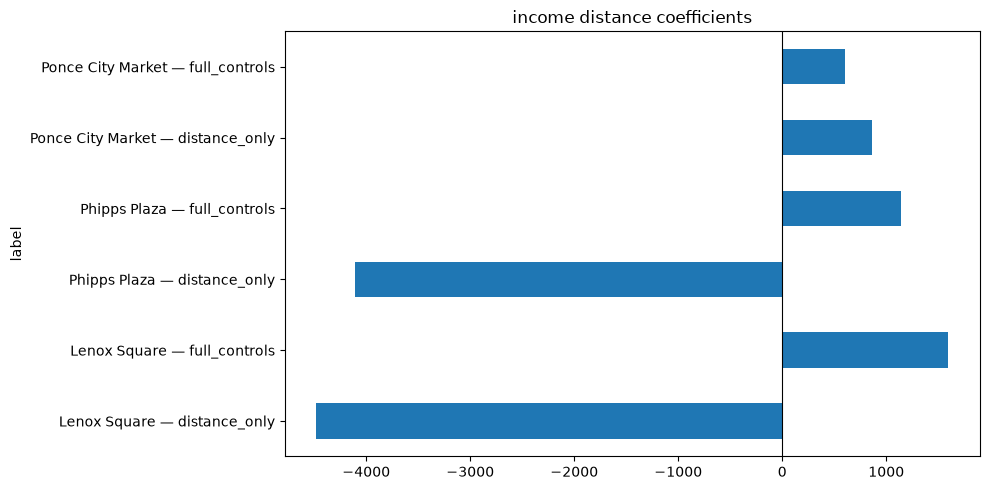

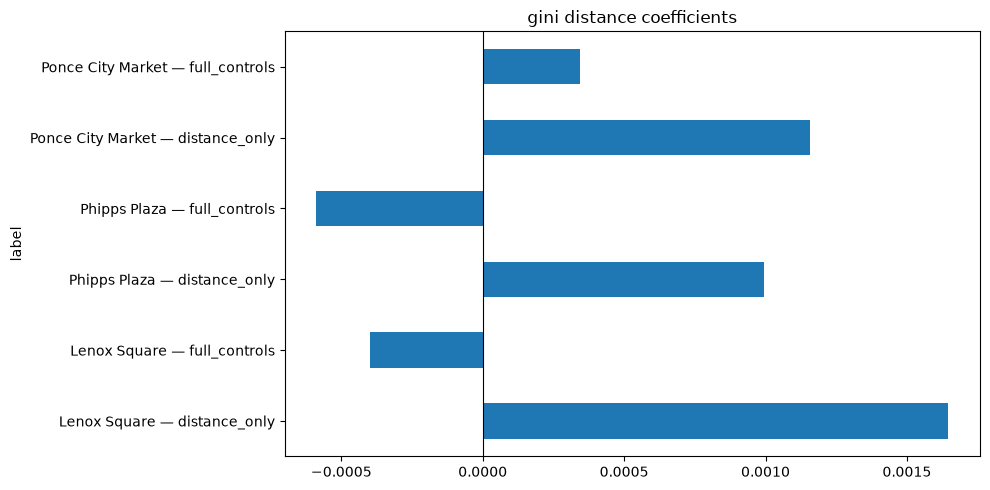

In [3]:
for outcome in ["income","gini"]:
 s=results[(results.outcome==outcome)&(results.model.isin(["distance_only","full_controls"]))].copy()
 s["label"]=s.mall+" — "+s.model
 ax=s.plot.barh(x="label",y="distance_coef",legend=False,figsize=(10,5),title=outcome+" distance coefficients")
 ax.axvline(0,color="black",linewidth=.8)
 plt.tight_layout();plt.show()

## Interpretation and cautions
- Education share = B15003_022E through _025E divided by B15003_001E (population age 25+).
- Poverty rate = S1701_C03_001E. Home value = B25077_001E.
- Income (B19013) and Gini (B19083) are 2024 ACS 5-year estimates.
- All three mall regressions reuse the same ZCTAs and should not be interpreted as independent experiments.
- Education, poverty, and home value are contemporaneous with income/Gini and potentially endogenous; coefficients are conditional associations, not causal effects.
- With 23–24 observations and correlated predictors, avoid overinterpreting isolated p-values; report robustness and uncertainty.
- Prior historical comparisons should be presented separately because overlapping ACS five-year windows complicate event-study identification.